# Problem 2 — Transformer from scratch
AI-assisted implementation under the professor permission reported by the user on 2026-11-09; disclose this assistance in the report. All models below use custom tensor attention and custom pre-LayerNorm blocks. Framework attention/Transformer layers occur only in reference tests.

## Task 1: scaled dot-product attention (10 marks)
q/k/v have shape `(B,H,T,Dh)`; output has the same shape and weights `(B,H,T,T)`. Boolean masks use **True=visible**, matching functional SDPA. Scores are `Q Kᵀ / sqrt(Dh)`, forbidden scores become negative infinity, and row-softmax weights multiply V. Every query must have at least one visible key. Attention dropout is applied on block outputs, not weights.

The instructor clarification requests our own three-token example. The small Q/K/V matrices and hand calculation below meet this requirement and are checked by code.

Mathematical reference: [Vaswani et al., Attention Is All You Need, section3.2.1/Eq1](https://arxiv.org/html/1706.03762v7#S3.SS2.SSS1). Our example is independently constructed; the paper supplies the mathematical definition. The assignment explicitly requires pre-LN, even though the original paper describes post-LN.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(101)
P2_RESULTS = {}

def check_close(actual, expected, label):
    assert isinstance(actual, torch.Tensor), label
    assert actual.shape == expected.shape, f'{label}: wrong shape'
    assert actual.dtype == expected.dtype and actual.device == expected.device, label
    assert torch.isfinite(actual).all(), f'{label}: nonfinite'
    error = (actual - expected).abs().max().item()
    assert error < 1e-5, f'{label}: max absolute error {error} >= 1e-5'
    return error

In [2]:
assert check_close(torch.ones(2), torch.ones(2), 'equal') == 0
for bad in (torch.zeros(2), torch.ones(3), torch.full((2,), float('nan'))):
    try:
        check_close(bad, torch.ones(2), 'deliberate invalid output')
    except AssertionError:
        pass
    else:
        raise AssertionError('Comparator accepted invalid output')
print('PASS: comparison helper negative controls; no student code verified')

PASS: comparison helper negative controls; no student code verified


In [3]:
def pending_or_check(name, check):
    P2_RESULTS[name] = 'In Progress'
    try:
        result = check()
    except NotImplementedError as exc:
        P2_RESULTS[name] = 'Blocked'
        print(f'PENDING {name}: {exc}')
    else:
        P2_RESULTS[name] = 'Verified'
        print(f'PASS {name}: {result}')

In [4]:
def _todo_probe():
    raise NotImplementedError('test-only unfinished probe')
pending_or_check('_probe', _todo_probe)
assert P2_RESULTS.pop('_probe') == 'Blocked'
print('PASS: unfinished checks cannot report success')

PENDING _probe: test-only unfinished probe
PASS: unfinished checks cannot report success


In [5]:
def verify_attention(candidate):
    worst = 0.0
    with torch.random.fork_rng(devices=[]):
        for dtype in (torch.float32, torch.float64):
            for seed in (101, 202):
                torch.manual_seed(seed)
                for batch, heads, length, width in ((1, 1, 3, 2), (2, 4, 7, 8)):
                    q, k, v = [torch.randn(batch, heads, length, width, dtype=dtype) for _ in range(3)]
                    causal = torch.ones(length, length, dtype=torch.bool).tril()
                    for allowed in (None, causal):
                        out, weights = candidate(q, k, v, allowed)
                        assert weights.shape == (batch, heads, length, length)
                        assert torch.isfinite(weights).all() and (weights >= 0).all()
                        worst = max(worst, check_close(weights.sum(-1), torch.ones_like(weights.sum(-1)), 'row sums'))
                        if allowed is not None:
                            assert torch.count_nonzero(weights[..., ~allowed]) == 0, 'Future information leaked'
                        reference = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, dropout_p=0.0)
                        worst = max(worst, check_close(out, reference, 'SDPA output'))
                        worst = max(worst, check_close(out, weights @ v, 'reported attention weights'))
    return {'max_abs_diff': worst}

In [6]:
# Deliberate bad output must be rejected by the actual attention verifier.
def _bad_attention(q, k, v, allowed=None):
    return torch.zeros_like(q), torch.zeros((*q.shape[:-1], k.shape[-2]), dtype=q.dtype)
try:
    verify_attention(_bad_attention)
except AssertionError:
    print('PASS: attention verifier rejects zero-sum weights')
else:
    raise AssertionError('Invalid attention accepted')

PASS: attention verifier rejects zero-sum weights


In [7]:
def scaled_dot_product_attention(q, k, v, allowed=None):
    # q/k: (B,H,T,Dh), v: (B,H,T,Dv). Supports different query/key lengths.
    if q.ndim != 4 or k.ndim != 4 or v.ndim != 4:
        raise ValueError('Expected four-dimensional q/k/v')
    if q.shape[:-2] != k.shape[:-2] or k.shape[:-2] != v.shape[:-2]:
        raise ValueError('Batch and head dimensions must match')
    if q.shape[-1] != k.shape[-1] or k.shape[-2] != v.shape[-2] or q.shape[-1] < 1:
        raise ValueError('Incompatible attention dimensions')
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    if allowed is not None:
        if allowed.dtype != torch.bool:
            raise ValueError('allowed must be a boolean mask')
        if not torch.broadcast_to(allowed, scores.shape).any(-1).all():
            raise ValueError('Every query needs at least one visible key')
        scores = scores.masked_fill(~allowed, float('-inf'))
    weights = scores.softmax(dim=-1)
    return weights @ v, weights

In [8]:
pending_or_check('attention', lambda: verify_attention(scaled_dot_product_attention))

PASS attention: {'max_abs_diff': 3.5762786865234375e-07}


### Our three-token hand calculation
Take all-zero queries and keys of width 2, and value rows `(1,0)`, `(0,2)`, `(3,4)`. Every unmasked score is zero. Without masking, all weights are 1/3 and each output row is `(4/3,2)`. With causal masking the weight rows are `(1,0,0)`, `(1/2,1/2,0)`, `(1/3,1/3,1/3)`; output rows are `(1,0)`, `(1/2,1)`, `(4/3,2)`. This checks masks and averaging; random tests above also check scaling and non-uniform attention. This is our chosen example as allowed by the instructor clarification. Explicitly, Q=K=[[0,0],[0,0],[0,0]], V=[[1,0],[0,2],[3,4]]. QKᵀ/√2 is a 3×3 zero matrix, so each unmasked weight is exp(0)/(3 exp(0))=1/3.

In [9]:
def verify_hand_example(candidate):
    q = torch.zeros(1, 1, 3, 2, dtype=torch.float64)
    values = torch.tensor([[[[1., 0.], [0., 2.], [3., 4.]]]], dtype=torch.float64)
    for allowed, expected_weights, expected_out in (
        (None, [[1/3]*3]*3, [[4/3, 2.]]*3),
        (torch.ones(3, 3, dtype=torch.bool).tril(),
         [[1.,0.,0.],[.5,.5,0.],[1/3,1/3,1/3]], [[1.,0.],[.5,1.],[4/3,2.]])):
        out, weights = candidate(q, q, values, allowed)
        check_close(weights, torch.tensor(expected_weights, dtype=q.dtype)[None,None], 'hand weights')
        check_close(out, torch.tensor(expected_out, dtype=q.dtype)[None,None], 'hand output')
    return 'Chosen three-token hand calculation matched'

In [10]:
pending_or_check('illustrative hand example', lambda: verify_hand_example(scaled_dot_product_attention))

PASS illustrative hand example: Chosen three-token hand calculation matched


### Nonuniform hand example (supplemental verification)
The original uniform example remains above. This example exercises the scale and nonuniform softmax. Let $a=1/\sqrt{2}$ and $E=e^a$. Chosen Q/K/V and scalar arithmetic below are independent expected values, checked against the existing implementation; no scratch function is changed.

In [11]:
# Hand oracle uses scalar exponentials, not the implementation's softmax.
a=1/math.sqrt(2); E=math.exp(a)
q=torch.tensor([[1.,0.],[0.,1.],[1.,1.]],dtype=torch.float64)
k=torch.tensor([[1.,0.],[0.,1.],[1.,-1.]],dtype=torch.float64)
v=torch.tensor([[1.,0.],[0.,2.],[3.,4.]],dtype=torch.float64)
hand_weights=torch.tensor([[E/(2*E+1),1/(2*E+1),E/(2*E+1)],
    [1/(1+E+1/E),E/(1+E+1/E),(1/E)/(1+E+1/E)],
    [E/(2*E+1),E/(2*E+1),1/(2*E+1)]],dtype=torch.float64)
# Two scalar weighted sums for each output row; QK^T rows are [1,0,1],[0,1,-1],[1,1,0].
hand_out=torch.tensor([[r[0]+3*r[2],2*r[1]+4*r[2]] for r in hand_weights.tolist()],dtype=q.dtype)
actual,weights=scaled_dot_product_attention(q[None,None],k[None,None],v[None,None])
check_close(weights[0,0],hand_weights,'nonuniform hand weights')
check_close(actual[0,0],hand_out,'nonuniform hand outputs')
print('PASS nonuniform hand attention; weights:',hand_weights,'output:',hand_out)


PASS nonuniform hand attention; weights: tensor([[0.4011, 0.1978, 0.4011],
        [0.2840, 0.5760, 0.1400],
        [0.4011, 0.4011, 0.1978]], dtype=torch.float64) output: tensor([[1.6044, 2.0000],
        [0.7041, 1.7121],
        [0.9944, 1.5933]], dtype=torch.float64)


## Multi-head attention — Task 2 (10 marks)
Use four biased `nn.Linear(d,d)` attributes named `q_proj`, `k_proj`, `v_proj`, `out_proj`. Constructor: `(d, heads)`, with d divisible by heads. Forward accepts `x` `(B,T,d)` and optional boolean `allowed`, and returns `(output, weights)` with shapes `(B,T,d)` and `(B,heads,T,T)`. Split feature width into heads, call your own attention, then combine heads and apply the output projection. No dropout inside this attention contract; encoder dropout is applied to branch outputs.

In [12]:
def verify_multihead(candidate_class):
    worst = 0.0
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(101)
        for heads in (1, 4, 8):
            d = 16
            custom = candidate_class(d, heads).double()
            reference = nn.MultiheadAttention(d, heads, dropout=0.0, batch_first=True).double()
            with torch.no_grad():
                for index, name in enumerate(('q_proj', 'k_proj', 'v_proj')):
                    projection = getattr(custom, name)
                    projection.weight.copy_(reference.in_proj_weight[index*d:(index+1)*d])
                    projection.bias.copy_(reference.in_proj_bias[index*d:(index+1)*d])
                    assert torch.equal(projection.weight, reference.in_proj_weight[index*d:(index+1)*d])
                    assert torch.equal(projection.bias, reference.in_proj_bias[index*d:(index+1)*d])
                custom.out_proj.load_state_dict(reference.out_proj.state_dict())
                for key, value in custom.out_proj.state_dict().items():
                    assert torch.equal(value, reference.out_proj.state_dict()[key])
                x = torch.randn(2, 5, d, dtype=torch.float64)
                for allowed in (None, torch.ones(5, 5, dtype=torch.bool).tril()):
                    actual, weights = custom(x, allowed)
                    expected, ref_weights = reference(x, x, x, attn_mask=None if allowed is None else ~allowed,
                                                      need_weights=True, average_attn_weights=False)
                    worst = max(worst, check_close(actual, expected, 'multi-head output'),
                                check_close(weights, ref_weights, 'per-head weights'))
            assert sum(p.numel() for p in custom.parameters()) == 4*d*d + 4*d
    return {'max_abs_diff': worst}

In [13]:
class MyMultiHeadAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        if d <= 0 or heads <= 0 or d % heads:
            raise ValueError('Positive d must be divisible by positive heads')
        self.d, self.heads = d, heads
        self.q_proj = nn.Linear(d, d)
        self.k_proj = nn.Linear(d, d)
        self.v_proj = nn.Linear(d, d)
        self.out_proj = nn.Linear(d, d)

    def forward(self, x, allowed=None):
        # (B,T,d) -> (B,H,T,d/H) -> (B,T,d), preserving head order.
        batch, length, width = x.shape
        if width != self.d:
            raise ValueError('Incorrect embedding width')
        def split(projection):
            return projection(x).reshape(batch, length, self.heads, width // self.heads).transpose(1, 2)
        output, weights = scaled_dot_product_attention(split(self.q_proj), split(self.k_proj),
                                                       split(self.v_proj), allowed)
        combined = output.transpose(1, 2).contiguous().reshape(batch, length, width)
        return self.out_proj(combined), weights

In [14]:
pending_or_check('multi-head', lambda: verify_multihead(MyMultiHeadAttention))

PASS multi-head: {'max_abs_diff': 1.8041124150158794e-16}


## Pre-LayerNorm encoder block 
Constructor `(d, heads, dropout=0.1)`; forward `(x, allowed=None)` returns a tensor `(B,T,d)`.
Use attributes `attention` (MyMultiHeadAttention), `norm1`, `norm2` (LayerNorm, eps=1e-5), `linear1` (d→4d), `linear2` (4d→d). All projections have biases; LayerNorm has learnable scale and bias. Use ReLU in the feed-forward branch (a documented free choice), with dropout after ReLU and on each residual branch output. Normalize **before** each branch; preserve residual additions. Use your own attention exclusively. Tests turn dropout off for deterministic comparison to a pre-norm PyTorch reference.

Weights: four attention matrices contribute `4d²`; feed-forward matrices contribute `2d*d_ff`. For d=128 and d_ff=512: **196608** weights. Attention biases add 4d; feed-forward biases add d_ff+d; two LayerNorms add 4d. Total: `196608 + 512 + 640 + 512 = 198272`. This count excludes embeddings, positional encodings, final norms and output heads.

In [15]:
def block_parameter_counts(d):
    weights = 4*d*d + 2*d*(4*d)
    return weights, weights + 4*d + (4*d+d) + 4*d

In [16]:
assert block_parameter_counts(128) == (196608, 198272)
reference_count = nn.TransformerEncoderLayer(128, 4, dim_feedforward=512, norm_first=True, batch_first=True)
assert sum(p.numel() for p in reference_count.parameters()) == 198272
print('PASS: block formula and reference total 198272; custom count checked below')
assert block_parameter_counts(64) == (49152, 49984)
# Actual custom model count is checked after its definition below.

PASS: block formula and reference total 198272; custom count checked below


In [17]:
def verify_encoder(candidate_class):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(101)
        d = 128
        custom = candidate_class(d, 4, dropout=0.0).double().eval()
        ref = nn.TransformerEncoderLayer(d, 4, dim_feedforward=4*d, dropout=0.0,
                                        activation='relu', batch_first=True, norm_first=True).double().eval()
        assert sum(p.numel() for p in custom.parameters()) == block_parameter_counts(d)[1]
        with torch.no_grad():
            for name in ('norm1', 'norm2', 'linear1', 'linear2'):
                getattr(custom, name).load_state_dict(getattr(ref, name).state_dict())
            for i, name in enumerate(('q_proj', 'k_proj', 'v_proj')):
                layer = getattr(custom.attention, name)
                layer.weight.copy_(ref.self_attn.in_proj_weight[i*d:(i+1)*d])
                layer.bias.copy_(ref.self_attn.in_proj_bias[i*d:(i+1)*d])
            custom.attention.out_proj.load_state_dict(ref.self_attn.out_proj.state_dict())
        x = torch.randn(2, 5, d, dtype=torch.float64)
        errors = []
        # Grad enabled avoids inference-only fused reference paths; no backward needed.
        for allowed in (None, torch.ones(5, 5, dtype=torch.bool).tril()):
            expected = ref(x, src_mask=None if allowed is None else ~allowed)
            errors.append(check_close(custom(x, allowed), expected, 'pre-LN encoder'))
        return {'params': 198272, 'max_abs_diff': max(errors)}

In [18]:
class MyEncoderBlock(nn.Module):
    def __init__(self, d, heads, dropout=0.1):
        super().__init__()
        self.attention = MyMultiHeadAttention(d, heads)
        self.norm1 = nn.LayerNorm(d, eps=1e-5)
        self.norm2 = nn.LayerNorm(d, eps=1e-5)
        self.linear1 = nn.Linear(d, 4*d)
        self.linear2 = nn.Linear(4*d, d)
        self.activation_dropout = nn.Dropout(dropout)
        self.attention_dropout = nn.Dropout(dropout)
        self.output_dropout = nn.Dropout(dropout)

    def forward(self, x, allowed=None):
        # Both residual streams retain shape (B,T,d); normalization precedes branches.
        attention, _ = self.attention(self.norm1(x), allowed)
        x = x + self.attention_dropout(attention)
        feedforward = self.linear2(self.activation_dropout(F.relu(self.linear1(self.norm2(x)))))
        return x + self.output_dropout(feedforward)

In [19]:
pending_or_check('encoder', lambda: verify_encoder(MyEncoderBlock))
assert sum(p.numel() for p in MyEncoderBlock(64, 4).parameters()) == 49984
print('PASS chosen d=64: 49152 weights + 832 biases/norm parameters = 49984')

PASS encoder: {'params': 198272, 'max_abs_diff': 8.881784197001252e-16}
PASS chosen d=64: 49152 weights + 832 biases/norm parameters = 49984


## Sinusoidal positions 
Implement `sinusoidal_positions(length, d)` returning float32 `(length,d)`, with d even for this contract. Position p, pair index i: even channel is sin(p/10000^(2i/d)), odd channel is cos(p/10000^(2i/d)). Build this with tensor operations. Add positions to embeddings in the models below; do not introduce learnable parameters for this variant.

In [20]:
def verify_positions(candidate):
    positions = candidate(7, 8)
    expected = torch.tensor([[math.sin(p / 10000**(2*i/8)) if channel % 2 == 0
                              else math.cos(p / 10000**(2*i/8))
                              for channel in range(8) for i in [channel//2]] for p in range(7)], dtype=torch.float32)
    error = check_close(positions, expected, 'sinusoidal positions')
    assert not positions.requires_grad
    assert not torch.equal(positions[0], positions[1])
    return {'max_abs_diff': error}

In [21]:
def sinusoidal_positions(length, d):
    if length < 1 or d < 2 or d % 2:
        raise ValueError('Positive length and even d >= 2 required')
    positions = torch.arange(length, dtype=torch.float32)[:, None]
    frequencies = torch.exp(torch.arange(0, d, 2, dtype=torch.float32) * (-math.log(10000.0) / d))
    angles = positions * frequencies
    result = torch.empty(length, d, dtype=torch.float32)
    result[:, 0::2], result[:, 1::2] = angles.sin(), angles.cos()
    return result

In [22]:
pending_or_check('positions', lambda: verify_positions(sinusoidal_positions))

PASS positions: {'max_abs_diff': 5.960464477539063e-08}


## Component acceptance
The strict gate reruns every numerical check; a skipped check cannot pass. Separate tests below compare input/parameter gradients, reject invalid masks and dimensions, and check causality through an entire block. The chosen three-token example is verified against the explicit hand-derived weights and outputs.

In [23]:
def require_problem2_components():
    return {'attention': verify_attention(scaled_dot_product_attention),
            'illustrative hand example': verify_hand_example(scaled_dot_product_attention),
            'multi-head': verify_multihead(MyMultiHeadAttention),
            'encoder': verify_encoder(MyEncoderBlock),
            'positions': verify_positions(sinusoidal_positions)}

print('Component status:', P2_RESULTS)
print('Strict component checks:', require_problem2_components())

Component status: {'attention': 'Verified', 'illustrative hand example': 'Verified', 'multi-head': 'Verified', 'encoder': 'Verified', 'positions': 'Verified'}


Strict component checks: {'attention': {'max_abs_diff': 3.5762786865234375e-07}, 'illustrative hand example': 'Chosen three-token hand calculation matched', 'multi-head': {'max_abs_diff': 1.8041124150158794e-16}, 'encoder': {'params': 198272, 'max_abs_diff': 8.881784197001252e-16}, 'positions': {'max_abs_diff': 5.960464477539063e-08}}


In [24]:
def verify_attention_gradients():
    torch.manual_seed(302)
    worst = 0.0
    for causal in (False, True):
        tensors = [torch.randn(2, 2, 5, 4, dtype=torch.float64, requires_grad=True) for _ in range(3)]
        refs = [x.detach().clone().requires_grad_() for x in tensors]
        mask = torch.ones(5, 5, dtype=torch.bool).tril() if causal else None
        out, _ = scaled_dot_product_attention(*tensors, mask)
        expected = F.scaled_dot_product_attention(*refs, attn_mask=mask)
        weights = torch.randn_like(out)
        actual_grads = torch.autograd.grad((out*weights).sum(), tensors)
        expected_grads = torch.autograd.grad((expected*weights).sum(), refs)
        for actual, target in zip(actual_grads, expected_grads):
            worst = max(worst, check_close(actual, target, 'attention backward'))
    return worst

In [25]:
print('PASS attention backward:', verify_attention_gradients())
for bad in (torch.zeros(3, 3, dtype=torch.bool), torch.ones(3, 3)):
    try:
        scaled_dot_product_attention(*[torch.randn(1,1,3,2) for _ in range(3)], bad)
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid mask accepted')
for d, heads in ((15,4), (0,4), (16,0)):
    try: MyMultiHeadAttention(d, heads)
    except ValueError: pass
    else: raise AssertionError('Invalid head dimensions accepted')
block = MyEncoderBlock(16,4,0).eval()
x = torch.randn(2,7,16); altered = x.clone(); altered[:,4:] += 100
mask = torch.ones(7,7,dtype=torch.bool).tril()
check_close(block(x,mask)[:,:4], block(altered,mask)[:,:4], 'block causality')
block.train(); block(x,mask).square().mean().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in block.parameters())
print('PASS invalid masks/dimensions, whole-block causality, finite parameter gradients')

PASS attention backward: 8.881784197001252e-16
PASS invalid masks/dimensions, whole-block causality, finite parameter gradients


# Problem 2 — Experiments
## Protocol and shared infrastructure
Chosen seeds are 0/1/2 and model width is d=64, as permitted by the instructor clarification. HAR uses 8-step patches (16 patches + CLS), d=64, two blocks, four heads, 10 epochs, Adam 1e-3, batch 128 and norm-1 clipping. All three positional variants use the exact P1 subject splits and training-only channel statistics. Compare to the P1 architecture selected by validation (GRU h64), with identical data/batch/epochs/optimizer; architecture, patching and dropout differ and are reported.

This CPU-only machine uses the assignment's explicit language-model exception: d=64, two layers (instead of d128/four layers), context128 and four heads. Fix five full training epochs, batch64, Adam1e-3, dropout0.1, clipping1.0. Vocabulary uses the whole text; training and validation are contiguous first90%/last10%, with no sequence shuffling. Fixed nonoverlapping next-character blocks omit fewer than128 final transitions per split. The 1/4/8-head and no-mask studies use identical budgets, seed0 and splits. No test/validation observation extends these budgets. Cache fingerprints include model/training source, config, data hashes and framework version. Completed runs are logged atomically before the next run.

In [26]:
from pathlib import Path
import copy
import hashlib
import json
import random
import time
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import Dataset, TensorDataset, DataLoader
ROOT = Path('.') if Path('problem2').is_dir() else Path('..')
DATA = ROOT/'data'
FIGURES = ROOT/'problem2'/'figures'
METRICS = ROOT/'problem2'/'metrics'
for directory in (DATA, FIGURES, METRICS): directory.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
SEEDS = (0,1,2)
CHANNELS = ('body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z',
            'total_acc_x','total_acc_y','total_acc_z')
RESULT_COLUMNS = 'problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes'.split(',')
HAR_CONFIG = dict(d=64, layers=2, heads=4, patch=8, dropout=.1, batch_size=128,
                  epochs=10, lr=.001, clip_norm=1., seeds=list(SEEDS))
LM_CONFIG = dict(d=128 if DEVICE.type=='cuda' else 64, layers=4 if DEVICE.type=='cuda' else 2,
                 heads=4, context=128, dropout=.1, batch_size=64, epochs=5, lr=.001,
                 clip_norm=1., seed=0, causal=True, top_k=20, generation_seed=700)
FORCE_P2_RERUN = False
print('Device:',DEVICE,'threads:',torch.get_num_threads(),'LM config:',LM_CONFIG)

Device: cpu threads: 4 LM config: {'d': 64, 'layers': 2, 'heads': 4, 'context': 128, 'dropout': 0.1, 'batch_size': 64, 'epochs': 5, 'lr': 0.001, 'clip_norm': 1.0, 'seed': 0, 'causal': True, 'top_k': 20, 'generation_seed': 700}


In [27]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def download_har(data_dir=DATA):
    """Download official archive, handling its optional nested ZIP."""
    destination = data_dir / 'har'
    found = [p for p in destination.rglob('UCI HAR Dataset') if (p / 'train' / 'y_train.txt').is_file()] if destination.exists() else []
    if found and (found[0] / 'test' / 'y_test.txt').exists():
        return found[0]
    archive = data_dir / 'har.zip'
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    if not archive.exists():
        temporary = archive.with_suffix('.download')
        urllib.request.urlretrieve(url, temporary)
        temporary.replace(archive)
    def extract(path, target):
        with zipfile.ZipFile(path) as z:
            # Reject archive members that escape the destination.
            for member in z.infolist():
                if not (target / member.filename).resolve().is_relative_to(target.resolve()):
                    raise ValueError('Unsafe ZIP member')
            z.extractall(target)
    extract(archive, destination)
    for nested in destination.rglob('*.zip'):
        extract(nested, nested.parent)
    found = [p for p in destination.rglob('UCI HAR Dataset') if (p / 'train' / 'y_train.txt').is_file()]
    if len(found) != 1:
        raise RuntimeError('Expected one UCI HAR Dataset directory')
    return found[0]

def load_har_split(root, split):
    if split not in ('train', 'test'):
        raise ValueError('split must be train or test')
    folder = root / split
    # Each channel is (windows, time); stack to (windows, time, channels).
    x = np.stack([np.loadtxt(folder / 'Inertial Signals' / f'{c}_{split}.txt',
                             dtype=np.float32) for c in CHANNELS], axis=-1)
    labels = np.loadtxt(folder / f'y_{split}.txt', dtype=np.int64)
    subjects = np.loadtxt(folder / f'subject_{split}.txt', dtype=np.int64)
    expected = 7352 if split == 'train' else 2947
    assert x.shape == (expected, 128, 9)
    assert labels.shape == subjects.shape == (expected,)
    assert np.array_equal(np.unique(labels), np.arange(1, 7))
    assert np.isfinite(x).all()
    return x, labels - 1, subjects  # CrossEntropyLoss requires labels 0..5.

def subject_split(subjects, seed):
    train_subjects = np.unique(subjects)
    held_out = np.random.default_rng(seed).choice(train_subjects, 4, replace=False)
    validation = np.isin(subjects, held_out)
    return np.flatnonzero(~validation), np.flatnonzero(validation), held_out

def fit_normalizer(training):
    # Pool windows and timesteps, preserving a broadcastable channel axis.
    mean = training.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
    std = training.std(axis=(0, 1), keepdims=True, dtype=np.float64)
    if np.any(std <= 0):
        raise ValueError('Cannot normalize a constant channel')
    return mean, std

def normalize(x, mean, std):
    return ((x - mean) / std).astype(np.float32)

def save_har_result(row, path):
    """Atomic upsert for a completed run; preserve other tasks/configurations."""
    frame = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=RESULT_COLUMNS)
    assert frame.columns.tolist() == RESULT_COLUMNS
    if len(frame):
        same = ((frame.problem == row['problem']) & (frame.model == row['model']) &
                (frame.seed == row['seed']) & (frame.notes == row['notes']))
        frame = frame.loc[~same]
    frame = pd.concat([frame, pd.DataFrame([row], columns=RESULT_COLUMNS)], ignore_index=True)
    temporary = path.with_suffix('.tmp')
    frame.to_csv(temporary, index=False)
    temporary.replace(path)

In [28]:
assert RESULT_COLUMNS == pd.read_csv(ROOT/'results.csv',nrows=0).columns.tolist()
HAR_DIR = download_har()
x_train_raw,y_train_raw,subjects_train = load_har_split(HAR_DIR,'train')
x_test_raw,y_test,subjects_test = load_har_split(HAR_DIR,'test')
assert not set(subjects_train) & set(subjects_test)
for seed in SEEDS:
    tr,va,held = subject_split(subjects_train,seed)
    assert len(held)==4 and not set(subjects_train[tr]) & set(subjects_train[va])
    mean,std = fit_normalizer(x_train_raw[tr])
    normalized = normalize(x_train_raw[tr],mean,std)
    assert np.max(np.abs(normalized.mean((0,1),dtype=np.float64))) < 1e-5
    assert np.max(np.abs(normalized.std((0,1),dtype=np.float64)-1)) < 1e-5
print('PASS: reused nine channels, labels, subject splits and training-only normalization')

PASS: reused nine channels, labels, subject splits and training-only normalization


## Task A: HAR encoder classifier (10 marks)
Flatten each 8×9 patch to72 channels, project to64, prepend learned CLS, add the selected positional representation (including CLS), run two custom pre-LN blocks and a final LayerNorm, then classify CLS into six activities. Positional variants otherwise have identical architecture. Learned positions add17×64 trainable parameters; sinusoidal/none add none.

In [29]:
class HAREncoder(nn.Module):
    def __init__(self, position, config):
        super().__init__()
        if position not in ('none','sinusoidal','learned'): raise ValueError(position)
        self.position, self.patch = position, config['patch']
        d, length = config['d'], 128//self.patch + 1
        if 128 % self.patch: raise ValueError('patch must divide 128')
        self.embedding = nn.Linear(9*self.patch,d)
        self.cls = nn.Parameter(torch.zeros(1,1,d))
        if position=='learned':
            self.positions = nn.Parameter(torch.empty(1,length,d))
            nn.init.normal_(self.positions,std=.02)
        else:
            fixed = sinusoidal_positions(length,d) if position=='sinusoidal' else torch.zeros(length,d)
            self.register_buffer('positions',fixed[None])
        self.blocks = nn.ModuleList([MyEncoderBlock(d,config['heads'],config['dropout'])
                                    for _ in range(config['layers'])])
        self.final_norm = nn.LayerNorm(d)
        self.classifier = nn.Linear(d,6)

    def forward(self,x):
        # (B,128,9) -> (B,16,72) -> (B,17,d), including CLS.
        batch,length,channels=x.shape
        if length!=128 or channels!=9: raise ValueError('HAR expects (B,128,9)')
        patches=x.reshape(batch,length//self.patch,channels*self.patch)
        x=torch.cat((self.cls.expand(batch,-1,-1),self.embedding(patches)),dim=1)
        x=x+self.positions
        for block in self.blocks: x=block(x)
        return self.classifier(self.final_norm(x)[:,0])

In [30]:
for position in ('none','sinusoidal','learned'):
    model=HAREncoder(position,HAR_CONFIG)
    logits=model(torch.randn(3,128,9)); assert logits.shape==(3,6)
    logits.square().mean().backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
    d=HAR_CONFIG['d']; expected=9*8*d+d+d+2*block_parameter_counts(d)[1]+2*d+6*d+6
    if position=='learned': expected+=17*d
    assert sum(p.numel() for p in model.parameters())==expected
    assert isinstance(model.positions,nn.Parameter)==(position=='learned')
# Without positions, CLS output is invariant to permutation of whole patches.
model=HAREncoder('none',HAR_CONFIG).eval(); x=torch.randn(2,16,8,9)
check_close(model(x.reshape(2,128,9)),model(x[:,torch.randperm(16)].reshape(2,128,9)), 'position-free patch invariance')
print('PASS HAR shape/parameters/backward/positional registration and patch-permutation invariance')

PASS HAR shape/parameters/backward/positional registration and patch-permutation invariance


## Task B: character-level causal language model (10 marks)
Vocabulary and contiguous split follow the official dataset instructions. The causal decoder reuses custom pre-LN blocks with a lower-triangular mask, fixed sinusoidal positions, a final LayerNorm and an untied character output projection. Forward returns logits `(B,T,65)`. Evaluation uses only within-validation next-character targets; no boundary crossing.

In [31]:
class CharacterTransformer(nn.Module):
    def __init__(self,vocab_size,config):
        super().__init__()
        self.config=dict(config)
        d=config['d']; self.embedding=nn.Embedding(vocab_size,d)
        self.register_buffer('positions',sinusoidal_positions(max(512,config['context']),d))
        self.blocks=nn.ModuleList([MyEncoderBlock(d,config['heads'],config['dropout'])
                                  for _ in range(config['layers'])])
        self.final_norm=nn.LayerNorm(d)
        self.output=nn.Linear(d,vocab_size)

    def forward(self,ids,return_attention=False):
        # ids (B,T) -> embeddings/logits (B,T,d)/(B,T,V).
        length=ids.shape[1]
        if length>len(self.positions): raise ValueError('Context exceeds positional buffer')
        x=self.embedding(ids)+self.positions[:length]
        allowed=torch.ones(length,length,dtype=torch.bool,device=ids.device).tril() if self.config['causal'] else None
        captured=[]
        for block in self.blocks:
            if return_attention:
                # Same actual branch weights; eval mode required to avoid dropout draws.
                if self.training: raise ValueError('Inspect attention in eval mode')
                captured.append(block.attention(block.norm1(x),allowed)[1])
            x=block(x,allowed)
        logits=self.output(self.final_norm(x))
        return (logits,captured) if return_attention else logits

class CharacterBlocks(Dataset):
    def __init__(self,ids,context):
        self.ids,self.context=ids,context
        if len(ids)<=context: raise ValueError('Split too short')
    def __len__(self): return (len(self.ids)-1)//self.context
    def __getitem__(self,index):
        if not 0<=index<len(self): raise IndexError(index)
        start=index*self.context
        return self.ids[start:start+self.context],self.ids[start+1:start+self.context+1]

In [32]:
tiny={**LM_CONFIG,'d':16,'layers':1,'heads':4,'context':8,'dropout':0.}
model=CharacterTransformer(65,tiny).eval(); ids=torch.randint(65,(2,8))
actual,weights=model(ids,True); assert actual.shape==(2,8,65) and weights[0].shape==(2,4,8,8)
changed=ids.clone(); changed[:,4:]=(changed[:,4:]+1)%65
check_close(model(ids)[:,:4],model(changed)[:,:4],'LM causality')
actual.square().mean().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
d=tiny['d']; assert sum(p.numel() for p in model.parameters())==65*d+block_parameter_counts(d)[1]+2*d+d*65+65
blocks=CharacterBlocks(torch.arange(25),8)
assert len(blocks)==3
for i in range(3):
    x,y=blocks[i]; assert torch.equal(y,x+1) and x[0].item()==i*8
print('PASS LM shape/count/backward/causality and contiguous next-character blocks')

PASS LM shape/count/backward/causality and contiguous next-character blocks


In [33]:
def prepare_shakespeare():
    path=DATA/'tiny_shakespeare'/'input.txt'; path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        temporary=path.with_suffix('.download')
        urllib.request.urlretrieve('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt',temporary)
        temporary.replace(path)
    text=path.read_text(encoding='utf-8')
    chars=sorted(set(text)); assert len(chars)==65
    stoi={char:i for i,char in enumerate(chars)}
    ids=torch.tensor([stoi[char] for char in text],dtype=torch.long)
    cut=int(.9*len(ids))
    return text,chars,stoi,ids[:cut],ids[cut:]

In [34]:
text,chars,stoi,train_ids,val_ids=prepare_shakespeare()
assert len(train_ids)==int(.9*len(text)) and len(val_ids)==len(text)-len(train_ids)
assert ''.join(chars[i] for i in val_ids[:100])==text[len(train_ids):len(train_ids)+100]
assert not torch.equal(train_ids[:128],val_ids[:128])
print('Shakespeare:',len(text),'characters; vocabulary',len(chars),'train',len(train_ids),'validation',len(val_ids))

Shakespeare: 1115394 characters; vocabulary 65 train 1003854 validation 111540


In [35]:
def evaluate_classifier(model,loader):
    model.eval(); predictions=[]; targets=[]; total_loss=0.
    with torch.no_grad():
        for x,y in loader:
            logits=model(x.to(DEVICE)); total_loss+=F.cross_entropy(logits,y.to(DEVICE),reduction='sum').item()
            predictions.extend(logits.argmax(-1).cpu().tolist()); targets.extend(y.tolist())
    return dict(loss=total_loss/len(targets),acc=accuracy_score(targets,predictions),
                f1=f1_score(targets,predictions,labels=list(range(6)),average='macro',zero_division=0),predictions=predictions)

def evaluate_language(model,loader):
    model.eval(); loss_sum=0.; count=0
    with torch.no_grad():
        for x,y in loader:
            logits=model(x.to(DEVICE)); targets=y.to(DEVICE)
            loss_sum+=F.cross_entropy(logits.flatten(0,1),targets.flatten(),reduction='sum').item()
            count+=targets.numel()
    return loss_sum/count

def synchronize():
    if DEVICE.type=='cuda': torch.cuda.synchronize()

def finish_run(key,config,result,state,extra=None):
    cache=P2_CACHE/key; cache.parent.mkdir(parents=True,exist_ok=True)
    checkpoint=dict(state_dict=state,config=config,source_hash=CODE_HASH,**(extra or {}))
    torch.save(checkpoint,cache.with_suffix('.pt'))
    temporary=cache.with_suffix('.tmp'); temporary.write_text(json.dumps(result,indent=2)); temporary.replace(cache.with_suffix('.json'))
    save_har_result(result['row'],ROOT/'results.csv')
    return result

def cached_run(key):
    cache=P2_CACHE/key
    if not FORCE_P2_RERUN and cache.with_suffix('.json').exists() and cache.with_suffix('.pt').exists():
        result=json.loads(cache.with_suffix('.json').read_text())
        assert result['source_hash']==CODE_HASH
        save_har_result(result['row'],ROOT/'results.csv'); print('CACHE',key,flush=True)
        return result
    return None

In [36]:
# Verify sample-weighted language loss against a uniform-logit fixture.
class UniformLM(nn.Module):
    def forward(self,x): return torch.zeros(*x.shape,65,device=x.device)
fixture=DataLoader(CharacterBlocks(torch.arange(25)%65,8),batch_size=2)
assert abs(evaluate_language(UniformLM(),fixture)-math.log(65))<1e-6
print('PASS token-weighted nats, including uneven final batch; uniform baseline',math.log(65))

PASS token-weighted nats, including uneven final batch; uniform baseline 4.174387269895637


In [37]:
def run_encoder(position,seed):
    config={**HAR_CONFIG,'position':position,'seed':seed}; key=f'har/{position}_{seed}'
    found=cached_run(key)
    if found is not None: return found
    seed_everything(seed)
    tr,va,held=subject_split(subjects_train,seed); mean,std=fit_normalizer(x_train_raw[tr])
    generator=torch.Generator().manual_seed(seed)
    def loader(x,y,shuffle=False):
        return DataLoader(TensorDataset(torch.from_numpy(normalize(x,mean,std)),torch.from_numpy(y)),
                          batch_size=config['batch_size'],shuffle=shuffle,generator=generator if shuffle else None)
    train_loader=loader(x_train_raw[tr],y_train_raw[tr],True)
    val_loader=loader(x_train_raw[va],y_train_raw[va])
    model=HAREncoder(position,config).to(DEVICE); optimizer=torch.optim.Adam(model.parameters(),lr=config['lr'])
    history=[]; best=-1.; best_state=None
    for epoch in range(1,config['epochs']+1):
        model.train(); synchronize(); start=time.perf_counter(); loss_sum=0.
        for x,y in train_loader:
            optimizer.zero_grad(set_to_none=True)
            loss=F.cross_entropy(model(x.to(DEVICE)),y.to(DEVICE)); assert torch.isfinite(loss)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),config['clip_norm'],error_if_nonfinite=True)
            optimizer.step(); loss_sum+=loss.item()*len(y)
        synchronize(); seconds=time.perf_counter()-start
        validation=evaluate_classifier(model,val_loader)
        history.append(dict(epoch=epoch,train_loss=loss_sum/len(tr),val_loss=validation['loss'],val_acc=validation['acc'],val_f1=validation['f1'],seconds=seconds))
        if validation['f1']>best:
            best=validation['f1']; best_epoch=epoch; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f'HAR {position} seed{seed} epoch{epoch}: valF1={validation["f1"]:.4f} sec={seconds:.2f}',flush=True)
    model.load_state_dict(best_state); test=evaluate_classifier(model,loader(x_test_raw,y_test))
    row=dict.fromkeys(RESULT_COLUMNS)
    row.update(problem='P2',model='HAR-Transformer-'+position,seed=seed,seq_len=128,test_acc=test['acc'],macro_f1=test['f1'],
               params=sum(p.numel() for p in model.parameters()),sec_per_epoch=float(np.mean([h['seconds'] for h in history])),
               notes=json.dumps(dict(task='P2_HAR',run_id=RUN_ID,**config),sort_keys=True))
    result=dict(source_hash=CODE_HASH,key=key,row=row,config=config,best_epoch=best_epoch,best_val_f1=best,
                held_subjects=held.tolist(),history=history,predictions=test['predictions'])
    return finish_run(key,config,result,best_state,dict(mean=torch.from_numpy(mean),std=torch.from_numpy(std)))

def run_language(heads=4,causal=True):
    config={**LM_CONFIG,'heads':heads,'causal':causal}; key=f'lm/heads{heads}_causal{int(causal)}'
    found=cached_run(key)
    if found is not None: return found
    seed_everything(config['seed'])
    train_loader=DataLoader(CharacterBlocks(train_ids,config['context']),batch_size=config['batch_size'],shuffle=False)
    val_loader=DataLoader(CharacterBlocks(val_ids,config['context']),batch_size=config['batch_size'],shuffle=False)
    model=CharacterTransformer(len(chars),config).to(DEVICE); optimizer=torch.optim.Adam(model.parameters(),lr=config['lr'])
    history=[]; best=float('inf'); best_state=None
    for epoch in range(1,config['epochs']+1):
        model.train(); synchronize(); start=time.perf_counter(); total_loss=0.; count=0
        for x,y in train_loader:
            optimizer.zero_grad(set_to_none=True); y=y.to(DEVICE)
            logits=model(x.to(DEVICE)); loss=F.cross_entropy(logits.flatten(0,1),y.flatten()); assert torch.isfinite(loss)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),config['clip_norm'],error_if_nonfinite=True)
            optimizer.step(); total_loss+=loss.item()*y.numel(); count+=y.numel()
        synchronize(); seconds=time.perf_counter()-start
        validation=evaluate_language(model,val_loader)
        history.append(dict(epoch=epoch,train_loss=total_loss/count,val_loss=validation,seconds=seconds))
        if validation<best:
            best=validation; best_epoch=epoch; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f'LM heads{heads} causal{causal} epoch{epoch}: train={total_loss/count:.4f} val={validation:.4f} sec={seconds:.2f}',flush=True)
    row=dict.fromkeys(RESULT_COLUMNS)
    row.update(problem='P2',model=f'Char-Transformer-h{heads}-'+('causal' if causal else 'unmasked'),seed=config['seed'],seq_len=config['context'],
               params=sum(p.numel() for p in model.parameters()),sec_per_epoch=float(np.mean([h['seconds'] for h in history])),
               val_loss_nats=best,bits_per_char=best/math.log(2),notes=json.dumps(dict(task='P2_LM',run_id=RUN_ID,**config),sort_keys=True))
    result=dict(source_hash=CODE_HASH,key=key,row=row,config=config,best_epoch=best_epoch,history=history)
    return finish_run(key,config,result,best_state,dict(chars=chars))

In [38]:
# Hash only declared dependency cells; figures/analysis additions do not retrain models.
_this_nb=nbformat.read(ROOT/'problem2'/'problem2.ipynb',4)
CODE_HASH=hashlib.sha256('\n'.join(c.source for c in _this_nb.cells if 'cache_dependency' in c.metadata.get('tags',[])).encode()).hexdigest()
HAR_DATA_HASH=hashlib.sha256(b''.join(a.tobytes() for a in (x_train_raw,y_train_raw,subjects_train,x_test_raw,y_test))).hexdigest()
TEXT_HASH=hashlib.sha256(text.encode()).hexdigest()
PROTOCOL=dict(har=HAR_CONFIG,lm=LM_CONFIG,code_hash=CODE_HASH,har_hash=HAR_DATA_HASH,text_hash=TEXT_HASH,
              torch=str(torch.__version__),device=str(DEVICE),threads=torch.get_num_threads())
RUN_ID=hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True).encode()).hexdigest()[:16]
P2_CACHE=DATA/'experiments'/'problem2'/RUN_ID; P2_CACHE.mkdir(parents=True,exist_ok=True)
(METRICS/'config.json').write_text(json.dumps(dict(run_id=RUN_ID,**PROTOCOL),indent=2))
print('Problem 2 run:',RUN_ID)

Problem 2 run: 13613c052b7f52c4


## Execute HAR positional ablation
Each completed run immediately persists a checkpoint, JSON history and shared CSV row. Three seeds use matched subject splits, loader seeds and the same fixed budget. Choose checkpoint by validation macro-F1, earliest tie.

In [39]:
har_results=[]
for position in ('none','sinusoidal','learned'):
    for seed in SEEDS: har_results.append(run_encoder(position,seed))
har_runs=pd.DataFrame([r['row'] for r in har_results]); har_runs.to_csv(METRICS/'har_runs.csv',index=False)
har_summary=har_runs.groupby('model').agg(acc_mean=('test_acc','mean'),acc_std=('test_acc','std'),
    f1_mean=('macro_f1','mean'),f1_std=('macro_f1','std'),params=('params','first'),seconds=('sec_per_epoch','mean'))
har_summary.to_csv(METRICS/'har_summary.csv')
pd.DataFrame([dict(position=r['config']['position'],seed=r['config']['seed'],**h) for r in har_results for h in r['history']]).to_csv(METRICS/'har_history.csv',index=False)
pd.DataFrame([dict(position=r['config']['position'],seed=r['config']['seed'],index=i,target=int(y_test[i]),prediction=p)
              for r in har_results for i,p in enumerate(r['predictions'])]).to_csv(METRICS/'har_predictions.csv',index=False)
assert len(har_results)==9
print(har_summary)

CACHE har/none_0


CACHE har/none_1


CACHE har/none_2


CACHE har/sinusoidal_0


CACHE har/sinusoidal_1


CACHE har/sinusoidal_2


CACHE har/learned_0


CACHE har/learned_1


CACHE har/learned_2


                            acc_mean   acc_std   f1_mean    f1_std  params  \
model                                                                        
HAR-Transformer-learned     0.912001  0.005304  0.912122  0.005724  106310   
HAR-Transformer-none        0.905441  0.018199  0.904461  0.018155  105222   
HAR-Transformer-sinusoidal  0.906119  0.010165  0.906158  0.010648  105222   

                             seconds  
model                                 
HAR-Transformer-learned     1.521261  
HAR-Transformer-none        1.418891  
HAR-Transformer-sinusoidal  1.544181  


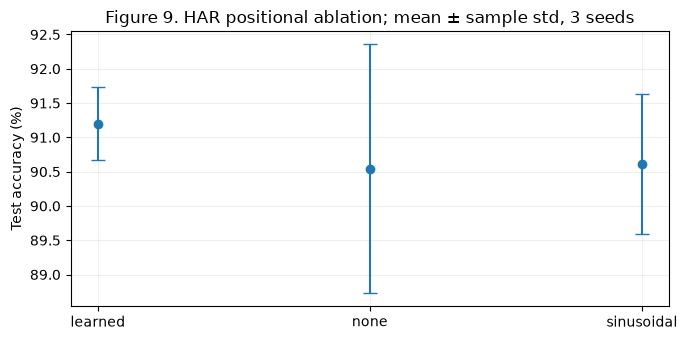

Validation-selected P1 baseline:
model  accuracy_mean  accuracy_std  macro_f1_mean  macro_f1_std  params  seconds_per_epoch_mean  seconds_per_epoch_std  validation_f1_mean
  GRU       0.881914      0.010354       0.881923       0.01041   14790                2.279295               0.021644            0.910429
 LSTM       0.877050      0.002926       0.876755       0.00234   19590                1.181613               0.040098            0.886326
  RNN       0.705237      0.049137       0.681398       0.04947    5190                0.677409               0.012044            0.712781


In [40]:
fig,ax=plt.subplots(figsize=(7,3.5))
x=np.arange(3); ax.errorbar(x,100*har_summary.acc_mean,yerr=100*har_summary.acc_std,fmt='o',capsize=5)
ax.set_xticks(x,[s.removeprefix('HAR-Transformer-') for s in har_summary.index]); ax.set_ylabel('Test accuracy (%)')
ax.set_title('Figure 9. HAR positional ablation; mean ± sample std, 3 seeds')
ax.grid(alpha=.2); fig.tight_layout(); fig.savefig(FIGURES/'har_positions.png',dpi=160); plt.show()
print('Validation-selected P1 baseline:')
print(pd.read_csv(ROOT/'problem1'/'metrics'/'har_summary.csv').to_string(index=False))

## Execute language model and fixed-budget ablations
Reuse the four-head causal run in the heads comparison. Removing the mask deliberately leaks future target tokens during training/validation; those losses are diagnostics and are not valid autoregressive quality estimates. Generated continuations use only the available prefix for both models.

In [41]:
lm_results=[]
for heads,causal in ((4,True),(1,True),(8,True),(4,False)):
    lm_results.append(run_language(heads,causal))
lm_runs=pd.DataFrame([r['row'] for r in lm_results]); lm_runs.to_csv(METRICS/'lm_runs.csv',index=False)
lm_history=pd.DataFrame([dict(heads=r['config']['heads'],causal=r['config']['causal'],**h) for r in lm_results for h in r['history']])
lm_history.to_csv(METRICS/'lm_history.csv',index=False)
assert len(lm_results)==4 and lm_runs.params.nunique()==1
assert np.allclose(lm_runs.bits_per_char,lm_runs.val_loss_nats/math.log(2),rtol=0,atol=1e-12)
print(lm_runs[['model','val_loss_nats','bits_per_char','params','sec_per_epoch']])

CACHE lm/heads4_causal1


CACHE lm/heads1_causal1


CACHE lm/heads8_causal1


CACHE lm/heads4_causal0


                          model  val_loss_nats  bits_per_char  params  \
0    Char-Transformer-h4-causal       2.234945       3.224344  108481   
1    Char-Transformer-h1-causal       2.202787       3.177949  108481   
2    Char-Transformer-h8-causal       2.255983       3.254695  108481   
3  Char-Transformer-h4-unmasked       0.317695       0.458337  108481   

   sec_per_epoch  
0      22.091084  
1      16.017674  
2      32.615598  
3      24.997464  


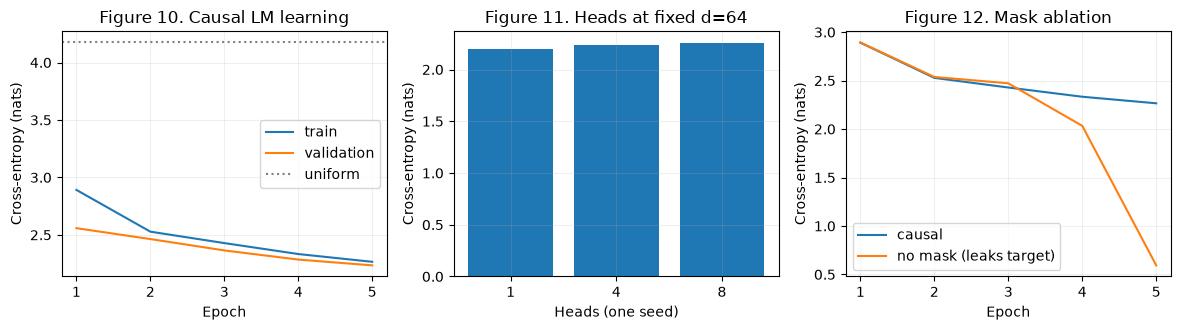

In [42]:
fig,axes=plt.subplots(1,3,figsize=(12,3.4))
base=lm_history[(lm_history.heads==4)&lm_history.causal]
axes[0].plot(base.epoch,base.train_loss,label='train'); axes[0].plot(base.epoch,base.val_loss,label='validation')
axes[0].axhline(math.log(65),ls=':',color='gray',label='uniform'); axes[0].set_title('Figure 10. Causal LM learning'); axes[0].legend()
head_runs=lm_runs[lm_runs.model.str.endswith('causal')].sort_values('model')
axes[1].bar([str(json.loads(v)['heads']) for v in head_runs.notes],head_runs.val_loss_nats)
axes[1].set_title('Figure 11. Heads at fixed d=64'); axes[1].set_xlabel('Heads (one seed)')
for causal in (True,False):
    rows=lm_history[(lm_history.heads==4)&(lm_history.causal==causal)]
    axes[2].plot(rows.epoch,rows.train_loss,label='causal' if causal else 'no mask (leaks target)')
axes[2].set_title('Figure 12. Mask ablation'); axes[2].legend()
for ax in axes: ax.set_ylabel('Cross-entropy (nats)'); ax.grid(alpha=.2)
axes[0].set_xlabel('Epoch'); axes[2].set_xlabel('Epoch'); fig.tight_layout()
fig.savefig(FIGURES/'lm_ablations.png',dpi=160); plt.show()

In [43]:
def load_language(result):
    checkpoint=torch.load((P2_CACHE/result['key']).with_suffix('.pt'),map_location='cpu',weights_only=True)
    assert checkpoint['chars']==chars and checkpoint['source_hash']==CODE_HASH
    model=CharacterTransformer(len(chars),result['config']).to(DEVICE)
    model.load_state_dict(checkpoint['state_dict']); return model.eval()

@torch.no_grad()
def generate_characters(model,prompt,temperature,new_characters=500,top_k=20,seed=700):
    if temperature<=0 or not 1<=top_k<=len(chars): raise ValueError('Invalid sampling settings')
    model.eval(); ids=torch.tensor([[stoi[c] for c in prompt]],device=DEVICE)
    generator=torch.Generator(device=DEVICE).manual_seed(seed)
    generated=[]
    for _ in range(new_characters):
        context=ids[:,-model.config['context']:]
        logits=model(context)[:,-1,:]/temperature
        values,indices=torch.topk(logits,top_k,dim=-1)
        choice=torch.multinomial(values.softmax(-1),1,generator=generator)
        next_id=indices.gather(-1,choice); generated.append(chars[next_id.item()])
        ids=torch.cat((ids,next_id),dim=1)
    return ''.join(generated)

In [44]:
main_model=load_language(lm_results[0]); prompt='ROMEO:\n'
# Deterministic restart checks use the actual validation-selected model.
a=generate_characters(main_model,prompt,.8,8,seed=700)
b=generate_characters(main_model,prompt,.8,8,seed=700)
assert a==b and len(a)==8
samples=[]
for temperature in (.2,.8,1.5):
    sample=generate_characters(main_model,prompt,temperature,500,LM_CONFIG['top_k'],LM_CONFIG['generation_seed'])
    assert len(sample)==500 and set(sample)<=set(chars)
    samples.append(dict(temperature=temperature,prompt=prompt,sample=sample,top_k=LM_CONFIG['top_k'],seed=LM_CONFIG['generation_seed']))
(METRICS/'samples.json').write_text(json.dumps(samples,indent=2))
(ROOT/'problem2'/'generated_samples.txt').write_text('\n\n'.join(
    f'Temperature {r["temperature"]}; top-k {r["top_k"]}; seed {r["seed"]}; 500 NEW characters; prompt {r["prompt"]!r}\n'+r['sample'] for r in samples))
unmasked=load_language(lm_results[-1]); no_mask_sample=generate_characters(unmasked,prompt,.8,500,LM_CONFIG['top_k'],LM_CONFIG['generation_seed'])
(METRICS/'no_mask_sample.txt').write_text(no_mask_sample)
assert len(no_mask_sample)==500
print('PASS: three labelled 500-character continuations; reproducible sampling; additional no-mask continuation saved')
for r in samples: print('Temperature',r['temperature'],repr(r['sample'][:160]))
print('No mask:',repr(no_mask_sample[:160]))

PASS: three labelled 500-character continuations; reproducible sampling; additional no-mask continuation saved
Temperature 0.2 'And he se the tere the to he the he the the the the the the he is the and the the is and to se to he and the the the and he he than sthe and the and the heand a'
Temperature 0.8 'HAnd I me harnt, you austie, deer\nt riot cot ad heat tul treaclin.\n\n\nWA:\nI lon ad be rof wof he ord in paret tence fend pas hirerelest ontalleds\nI your I miours'
Temperature 1.5 "HAnd:\nThaker fen' mO!\nLOUTIOOf has:\nG:\nBud bew'l fra, bird.\nWhick'sh bucwe cot t sthe! nomo, hols held dardy;\nWame fe tho m tall ayntheserod mil tume arre sthar"
No mask: '\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n?.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


## Task 5(a): attention inspection
Inspect layer1 heads1 and2 of the trained causal model on a fixed sentence from the permitted vocabulary. Rows are queries, columns keys. Future positions must remain exactly zero. These are attention patterns, not causal explanations of the generated text.

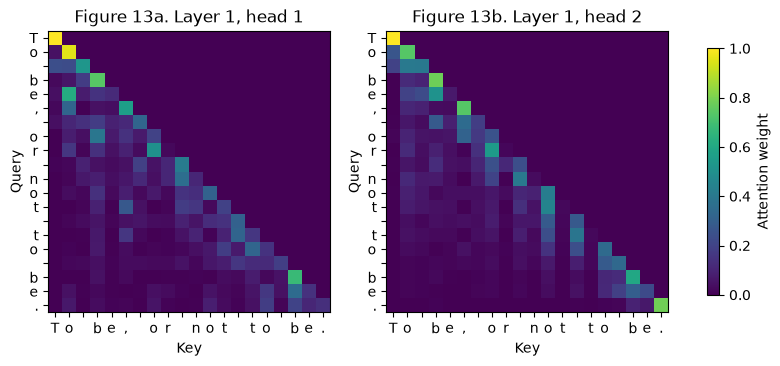

Mean attention to first token: [0.07208553 0.07468791]
Mean attention to current token: [0.36161736 0.3736096 ]


In [45]:
sentence='To be, or not to be.'
main_model.eval()
with torch.no_grad():
    _,attentions=main_model(torch.tensor([[stoi[c] for c in sentence]],device=DEVICE),True)
weights=attentions[0][0,:2].cpu().numpy()
assert np.count_nonzero(weights[:,np.triu_indices(len(sentence),1)[0],np.triu_indices(len(sentence),1)[1]])==0
np.savez(METRICS/'attention_heads.npz',weights=weights,sentence=sentence)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for index,ax in enumerate(axes):
    im=ax.imshow(weights[index],vmin=0,vmax=1,cmap='viridis')
    ax.set_xticks(range(len(sentence)),list(sentence)); ax.set_yticks(range(len(sentence)),list(sentence))
    ax.set_title(f'Figure 13{chr(97+index)}. Layer 1, head {index+1}'); ax.set_xlabel('Key'); ax.set_ylabel('Query')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.8,label='Attention weight')
fig.savefig(FIGURES/'attention_heads.png',dpi=160,bbox_inches='tight'); plt.show()
print('Mean attention to first token:',weights[:,:,0].mean(axis=1))
print('Mean attention to current token:',np.diagonal(weights,axis1=1,axis2=2).mean(axis=1))

## Task 5(d): measured context scaling
Benchmark the same trained causal model at contexts64/128/256/512, batch8, float32, dropout off. Five timed forward+backward passes follow two warmups; synchronize CUDA if present. CPU memory is the peak live tensor allocation reconstructed from PyTorch profiler memory events, relative to the pre-profile baseline (excludes interpreter/model weights and allocator reservation). CUDA uses peak allocated bytes above the model/input baseline. Exact profiler results and matrix-element counts are saved. Increasing context at fixed width makes the attention score tensor quadratic; total model time/memory also include linear feed-forward and embedding costs.

In [46]:
def context_benchmark(model,length,batch=8,repeats=5):
    model.eval(); ids=torch.arange(batch*length,device=DEVICE).reshape(batch,length)%len(chars)
    def step():
        model.zero_grad(set_to_none=True)
        loss=model(ids).square().mean(); loss.backward()
    for _ in range(2): step()
    times=[]
    for _ in range(repeats):
        synchronize(); start=time.perf_counter(); step(); synchronize(); times.append(time.perf_counter()-start)
    model.zero_grad(set_to_none=True)
    if DEVICE.type=='cuda':
        torch.cuda.reset_peak_memory_stats(); baseline=torch.cuda.memory_allocated(); step(); synchronize()
        peak=torch.cuda.max_memory_allocated()-baseline
    else:
        # Raw allocation events, not nested operator totals (which double-count).
        with torch.profiler.profile(activities=[torch.profiler.ProfilerActivity.CPU],profile_memory=True) as profiler:
            step()
        events=[]
        for event in profiler.profiler.kineto_results.events():
            if event.name()=='[memory]':
                events.append((event.start_ns(),event.nbytes()))
        current=0; peak=0
        for _,delta in sorted(events):
            current+=delta; peak=max(peak,current)
        assert events and peak>0
        traces=[]
        for trial in range(3):
            if trial:
                model.zero_grad(set_to_none=True)
                with torch.profiler.profile(activities=[torch.profiler.ProfilerActivity.CPU],profile_memory=True) as repeat_profiler:
                    step()
                events=[(e.start_ns(),e.nbytes()) for e in repeat_profiler.profiler.kineto_results.events() if e.name()=='[memory]']
            current=0; trial_peak=0; origin=min(t for t,_ in events)
            ordered=sorted(events)
            for _,delta in ordered:
                current+=delta; trial_peak=max(trial_peak,current)
            traces.append(dict(trial=trial,peak_bytes=trial_peak,
                               events_ns_bytes=[[int(t-origin),int(delta)] for t,delta in ordered]))
        peak=int(np.median([t['peak_bytes'] for t in traces]))
        (METRICS/f'context_raw_{length}.json').write_text(json.dumps(dict(
            context=length,batch=batch,dtype=str(next(model.parameters()).dtype),
            threads=torch.get_num_threads(),torch=str(torch.__version__),device=str(DEVICE),
            mode='eval forward + backward; squared logits; two warmups; additional live tensors',
            timing_seconds=times,memory_trials=traces),indent=2))
    model.zero_grad(set_to_none=True)
    return dict(context=length,batch=batch,mean_seconds=float(np.mean(times)),std_seconds=float(np.std(times,ddof=1)),
                peak_incremental_bytes=peak,attention_score_elements=batch*model.config['heads']*length*length,
                device=str(DEVICE),repeats=repeats)

USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start


USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop


USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:09 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop


USDT:2026-11-09 17:54:11 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:11 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:11 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start


USDT:2026-11-09 17:54:11 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-09 17:54:11 32267:32267 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-09 17:54:11 32267:32267 SyncActivityProfilerHandler.cpp:46] profiler_stop


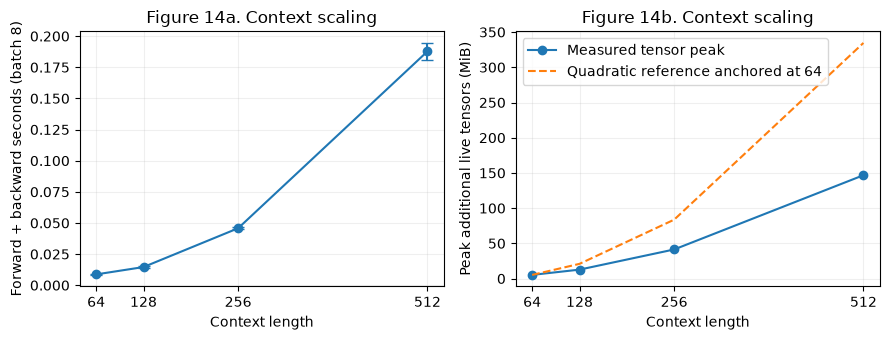

 context  batch  mean_seconds  std_seconds  peak_incremental_bytes  attention_score_elements device  repeats
      64      8      0.008709     0.000402                 5481756                    131072    cpu        5
     128      8      0.014602     0.000810                13331484                    524288    cpu        5
     256      8      0.045767     0.000897                43338780                   2097152    cpu        5
     512      8      0.187750     0.006799               153881628                   8388608    cpu        5


In [47]:
scaling=pd.DataFrame([context_benchmark(main_model,length) for length in (64,128,256,512)])
assert len(scaling)==4 and (scaling.peak_incremental_bytes>0).all() and (scaling.mean_seconds>0).all()
scaling.to_csv(METRICS/'context_scaling.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
axes[0].errorbar(scaling.context,scaling.mean_seconds,yerr=scaling.std_seconds,marker='o',capsize=4)
axes[0].set_ylabel('Forward + backward seconds (batch 8)')
axes[1].plot(scaling.context,scaling.peak_incremental_bytes/2**20,'o-',label='Measured tensor peak')
reference=scaling.peak_incremental_bytes.iloc[0]*(scaling.context/64)**2/2**20
axes[1].plot(scaling.context,reference,'--',label='Quadratic reference anchored at 64')
axes[1].set_ylabel('Peak additional live tensors (MiB)'); axes[1].legend()
for index,ax in enumerate(axes):
    ax.set_xlabel('Context length'); ax.set_xticks(scaling.context); ax.grid(alpha=.2)
    ax.set_title(f'Figure 14{chr(97+index)}. Context scaling')
fig.tight_layout(); fig.savefig(FIGURES/'context_scaling.png',dpi=160); plt.show()
print(scaling.to_string(index=False))

## Additional measured diagnostics and interpretation
Future-token perturbation tests distinguish causal and unmasked trained models. Sample statistics describe these particular seeded continuations, not model entropy or a statistical comparison across multiple generated runs.

In [48]:
def sample_statistics(sample):
    from collections import Counter
    counts=np.array(list(Counter(sample).values()),dtype=np.float64)
    probabilities=counts/counts.sum()
    return dict(distinct_characters=len(counts),empirical_char_entropy_bits=float(-(probabilities*np.log2(probabilities)).sum()),
                repeated_adjacent_fraction=sum(a==b for a,b in zip(sample,sample[1:]))/(len(sample)-1),
                newline_fraction=sample.count('\n')/len(sample))

In [49]:
assert sample_statistics('aaaa')['distinct_characters']==1
assert sample_statistics('aaaa')['empirical_char_entropy_bits']==0
assert sample_statistics('abab')['empirical_char_entropy_bits']==1
sample_stats=pd.DataFrame([dict(model='causal',temperature=s['temperature'],**sample_statistics(s['sample'])) for s in samples]+
                          [dict(model='unmasked',temperature=.8,**sample_statistics(no_mask_sample))])
sample_stats.to_csv(METRICS/'sample_statistics.csv',index=False)
ids=torch.tensor([[stoi[c] for c in sentence]],device=DEVICE)
changed=ids.clone(); changed[:,5:]=(changed[:,5:]+1)%len(chars)
with torch.no_grad():
    causal_difference=(main_model(ids)[:,:5]-main_model(changed)[:,:5]).abs().max().item()
    unmasked_difference=(unmasked(ids)[:,:5]-unmasked(changed)[:,:5]).abs().max().item()
assert causal_difference<1e-5 and unmasked_difference>1e-5
mask_diagnostic=dict(causal_prefix_max_change=causal_difference,unmasked_prefix_max_change=unmasked_difference,
                    diagonal_attention_means=np.diagonal(weights,axis1=1,axis2=2).mean(axis=1).tolist(),
                    first_token_attention_means=weights[:,:,0].mean(axis=1).tolist())
(METRICS/'mask_diagnostic.json').write_text(json.dumps(mask_diagnostic,indent=2))
print(sample_stats.to_string(index=False)); print('Trained-mask diagnostic:',mask_diagnostic)
print('512/64 ratios: time',scaling.mean_seconds.iloc[-1]/scaling.mean_seconds.iloc[0],
      'tensor peak',scaling.peak_incremental_bytes.iloc[-1]/scaling.peak_incremental_bytes.iloc[0])

   model  temperature  distinct_characters  empirical_char_entropy_bits  repeated_adjacent_fraction  newline_fraction
  causal          0.2                   14                     2.920343                    0.000000             0.000
  causal          0.8                   31                     4.167316                    0.028056             0.022
  causal          1.5                   44                     4.687533                    0.044088             0.042
unmasked          0.8                    4                     0.135330                    0.969940             0.984
Trained-mask diagnostic: {'causal_prefix_max_change': 0.0, 'unmasked_prefix_max_change': 7.153540134429932, 'diagonal_attention_means': [0.3616173565387726, 0.37360960245132446], 'first_token_attention_means': [0.07208552956581116, 0.0746879130601883]}
512/64 ratios: time 21.55904816839009 tensor peak 28.07159384693518


## Problem 2 analysis
Figure9 and the HAR summary show no clear test advantage of sinusoidal versus no global positions under this budget; local order inside each8-step patch remains available. Validation selects sinusoidal, although learned has the highest test mean. Compare its105222 parameters and17-token computation with the selected recurrent GRU's14790 parameters and128 recurrent steps; this backend's timing does not measure wearable energy.

Figure10 shows the CPU-exception four-head model still improving at epoch5 (2.23495nats,3.22434BPC), outside the larger/longer-trained model's approximate sanity range. Figure11 gives one-head/four-head/eight-head validation2.20279/2.23495/2.25598 at equal108481 parameter counts; one seed does not establish a general ranking. Figure12's no-mask loss collapse reflects access to future target tokens. Its500-character generation collapses mainly to newlines; the trained-model perturbation test above directly demonstrates future dependence.

At temperature0.2, the actual sample repeatedly uses short high-probability fragments such as `the` and `and`. Temperature0.8 increases wordlike variation, line breaks and speaker-like fragments while retaining misspellings. Temperature1.5 mixes case and punctuation more often, with less coherent spelling. All three are weak language-model samples; top-k20 is fixed, and the sample statistics above describe only these draws.

Figure13's heads both favor the diagonal/current character and nearby history, with differing weight patterns; all future entries are zero. They do not demonstrate linguistic specialization on one short sentence. In Figure14, increasing context8× increases a score tensor64×. Measured full-model memory/time include linear embedding/FFN work as well as quadratic attention, so ratios need not equal64. CPU peak here is additional live tensor allocation, not total process RSS or reserved GPU memory. No claims are made about long-context quality or T4 speed. See `docs/problem2-results.md` for the numbered tables, exact measurements and limitations.

## Acceptance evidence and remaining limitation
Reference and assertion cells must pass before training. All experiment metrics above are measured, with validation-selected checkpoints and saved histories. No-mask validation loss is contaminated by future information and is not an autoregressive metric. Final report analysis must use the actual tables/plots/samples. Our chosen three-token Q/K/V example and its hand/code agreement satisfy the clarified requirement. Full notebook Restart & Run All is validated by `scripts/execute_problem2.py`.